## Aircraft Routing Base Case Test

In [1]:
using CSV, DataFrames, JuMP, Gurobi, Plots
using LaTeXStrings, StatsPlots, LinearAlgebra

In [2]:
city_coords = CSV.read("data/cities.csv", DataFrame);
aircraft_costs = CSV.read("data/costs.csv", DataFrame);
aircraft_ranges = CSV.read("data/ranges.csv", DataFrame);

In [3]:
C = Matrix(city_coords);
O = Matrix(aircraft_costs);
R = Matrix(aircraft_ranges);

In [4]:
aircraft = 1:size(O,1);
all_cities = 1:size(C,1);
cities_nofirst = 2:size(C,1);
cities_nolast = 1:size(C,1)-1;
cities_nohub = 2:size(C,1)-1;

In [5]:
# Define distance function
function distance(x_1::Float64, y_1::Float64, x_2::Float64, y_2::Float64)::Float64
    deltax = x_1 - x_2;
    deltay = y_1 - y_2;
    d = sqrt(deltax^2 + deltay^2);
    return d
end

distance (generic function with 1 method)

In [6]:
model = Model(Gurobi.Optimizer);

Set parameter Username
Academic license - for non-commercial use only - expires 2024-09-07


In [7]:
@variable(model, X[all_cities,all_cities,aircraft], Bin);

In [8]:
@objective(model, Min,
    sum(sum(sum(O[k] * distance(C[i,1],C[i,2],C[j,1],C[j,2]) * X[i,j,k]
                for j in all_cities)
            for i in all_cities)
        for k in aircraft)
    );

In [9]:
@constraint(model, one_departure_per_city[i in cities_nohub],
    sum(sum(X[i,j,k] for j in cities_nofirst) for k in aircraft) == 1);
@constraint(model, same_arrival_as_departure[i in cities_nohub, k in aircraft],
    sum(X[j,i,k] for j in cities_nolast) == sum(X[i,j,k] for j in cities_nofirst));
@constraint(model, all_aircraft_depart_hub[k in aircraft],
    sum(X[1,j,k] for j in cities_nofirst) == 1);
@constraint(model, all_aircraft_return_hub[k in aircraft],
    sum(X[i,12,k] for i in cities_nolast) == 1);

# These constraints weren't given on the slides but are necessary
# to avoid a trivial solution
@constraint(model, no_duplication[i in all_cities, k in aircraft],
    X[i,i,k] == 0);
@constraint(model, no_duplication_hub[k in aircraft],
    X[1,12,k] + X[12,1,k] == 0);

# Maybe this is too restrictive - it could be interesting to work with the case where
# an aircraft returns through the same path where it traveled
@constraint(model, directionality[i in all_cities, j in all_cities, k in aircraft],
    X[i,j,k] + X[j,i,k] <= 1);
# Note that this alone still allows a round-trip for (1,j) to (j,12), which we 
# may or may not want to restrict

# Try directionality on hub too
@constraint(model, directionality_hub[j in cities_nohub, k in aircraft],
    X[1,j,k] + X[j,12,k] <= 1);

# nnodes = (size(C,1) - 1);
# @constraint(model, connectedness,
#     sum(sum(sum(X[i,j,k] for j in all_cities)
#             for i in all_cities)
#         for k in aircraft) >= nnodes - 1);

@constraint(model, range_limit[i in all_cities, j in all_cities, k in aircraft],
    distance(C[i,1],C[i,2],C[j,1],C[j,2]) * X[i,j,k] <= R[k]);

# TODO: Need constraint to enforce no islands
# ...

In [10]:
optimize!(model)

Gurobi Optimizer version 10.0.2 build v10.0.2rc0 (win64)

CPU model: 12th Gen Intel(R) Core(TM) i7-1255U, instruction set [SSE2|AVX|AVX2]
Thread count: 10 physical cores, 12 logical processors, using up to 12 threads

Optimize a model with 979 rows, 432 columns and 2316 nonzeros
Model fingerprint: 0x1f2461a3
Variable types: 0 continuous, 432 integer (432 binary)
Coefficient statistics:
  Matrix range     [1e+00, 2e+02]
  Objective range  [2e+00, 3e+02]
  Bounds range     [0e+00, 0e+00]
  RHS range        [1e+00, 8e+01]
Presolve removed 960 rows and 413 columns
Presolve time: 0.02s
Presolved: 19 rows, 19 columns, 58 nonzeros
Variable types: 0 continuous, 19 integer (19 binary)
Found heuristic solution: objective 909.7273142

Root relaxation: cutoff, 11 iterations, 0.00 seconds (0.00 work units)

    Nodes    |    Current Node    |     Objective Bounds      |     Work
 Expl Unexpl |  Obj  Depth IntInf | Incumbent    BestBd   Gap | It/Node Time

     0     0     cutoff    0       909.7273

In [11]:
Xopt = Array(value.(X[:,:,:]));

[1,11,1]
[10,12,1]
[11,10,1]
[1,3,2]
[2,12,2]
[3,2,2]
[1,7,3]
[4,6,3]
[5,12,3]
[6,9,3]
[7,8,3]
[8,4,3]
[9,5,3]


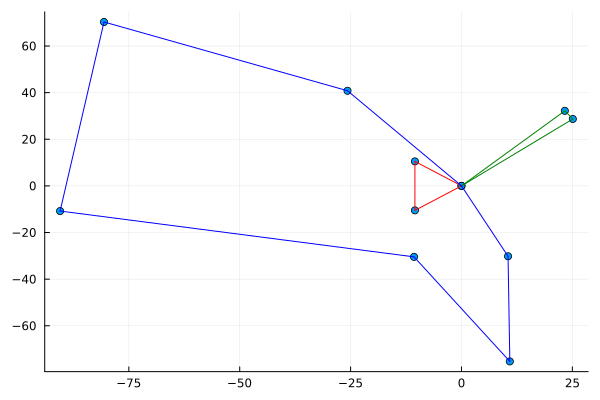

In [12]:
fig = scatter(C[:,1], C[:,2], legend=false);
for k in aircraft
    for i in all_cities
        for j in all_cities
            if (Xopt[i,j,k] > 0.95) 
                print("[" * string(i) * "," * string(j) * "," * string(k) * "]")
                print("\n")
                xcoords = [C[i,1];C[j,1]];
                ycoords = [C[i,2];C[j,2]];
                if (k == 1)
                    plot!(fig, xcoords, ycoords, color=:red);
                elseif (k == 2)
                    plot!(fig, xcoords, ycoords, color=:green);
                elseif (k == 3)
                    plot!(fig, xcoords, ycoords, color=:blue);
                end
            end
        end
    end
end
fig